In [1]:
import numpy as np 
import pandas  as pd 

from sklearn.model_selection import train_test_split 

import matplotlib.pyplot as plt 
import seaborn as sns

In [2]:
df = pd.read_csv('train.csv', usecols=['Age','Fare', 'Survived'])

In [3]:
df.head()


,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [4]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [5]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [6]:
X_train,X_test,y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [7]:
X_train['Age_imputed']= X_train['Age']
X_test['Age_imputed'] = X_test['Age']

In [8]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,NaN
493,71.0,49.5042,71.0
527,NaN,221.7792,NaN


In [9]:
# X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
# X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_test['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

In [10]:
# 1. Determine how many missing values need to be filled
train_null_count = X_train['Age_imputed'].isnull().sum()
test_null_count = X_test['Age_imputed'].isnull().sum()

# 2. Extract random samples from the training set's non-null Age values to avoid data leakage
# (Sampling from X_train for both ensures test set behavior mimics the train distribution)
sampled_train_values = X_train['Age'].dropna().sample(train_null_count, replace=True).values
sampled_test_values = X_train['Age'].dropna().sample(test_null_count, replace=True).values

# 3. Safely fill the missing rows using .loc
X_train.loc[X_train['Age_imputed'].isnull(), 'Age_imputed'] = sampled_train_values
X_test.loc[X_test['Age_imputed'].isnull(), 'Age_imputed'] = sampled_test_values


In [11]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([31.  , 36.  , 49.  , 40.  , 19.  , 34.  ,  6.  , 23.  , 36.  ,
       32.  , 24.  , 22.  , 42.  , 35.  , 36.5 , 21.  , 22.  , 23.  ,
       20.  , 25.  , 22.  , 24.  , 24.  , 30.  , 24.  , 15.  ,  6.  ,
       24.  , 17.  , 36.  , 17.  , 30.  , 19.  , 50.  , 21.  , 32.  ,
       18.  , 28.  ,  1.  , 36.  ,  2.  , 45.  , 19.  , 29.  , 26.  ,
       24.  ,  3.  , 51.  , 31.  , 38.  , 28.5 , 52.  ,  1.  , 21.  ,
       38.  , 21.  , 27.  ,  3.  , 22.  ,  2.  , 29.  , 34.  , 19.  ,
       14.  , 39.  ,  9.  , 18.  , 22.  , 40.  , 33.  , 30.  , 42.  ,
       26.  , 37.  , 42.  , 18.  , 23.  , 32.  , 28.  , 18.  , 41.  ,
       34.  , 33.  , 36.  , 16.  ,  9.  ,  0.75, 65.  , 35.  , 23.  ,
       22.  , 30.  , 27.  , 13.  , 18.  , 45.  , 56.  , 49.  , 23.5 ,
       19.  , 32.  , 58.  , 14.  ,  2.  , 18.  , 32.  , 30.  , 43.  ,
       23.  , 40.  , 65.  , 27.  , 24.  , 21.  ,  4.  , 32.5 , 16.  ,
       34.  , 52.  , 46.  , 40.  , 49.  ,  5.  , 21.  , 17.  , 44.  ,
       27.  , 14.  ,

In [12]:
X_train['Age'].isnull().sum()

np.int64(148)

In [13]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,20.0
493,71.0,49.5042,71.0
527,NaN,221.7792,22.0


C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1393040810.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['Age'],label='Original',hist=False)
C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1393040810.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train['A

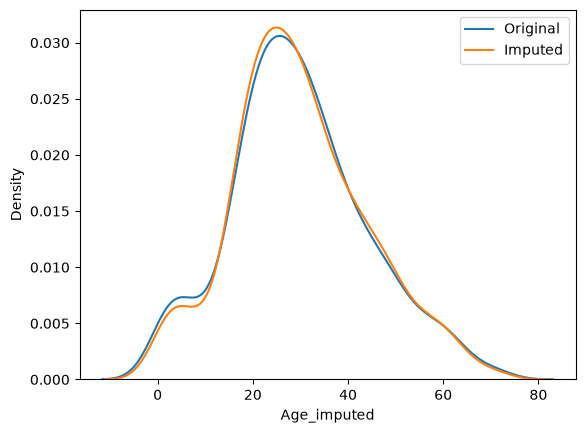

In [14]:
sns.distplot(X_train['Age'],label='Original',hist=False)
sns.distplot(X_train['Age_imputed'],label='Imputed',hist=False)

plt.legend()
plt.show()

In [15]:
print('Original_variables variance:', X_train['Age'].var())
print('variance after random imutation:', X_train['Age_imputed'].var())

Original_variables variance: 204.34951339046142
variance after random imutation: 196.86246749454796


In [16]:
X_train[['Fare','Age','Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,62.394392
Age,71.512440,204.349513,204.349513
Age_imputed,62.394392,204.349513,196.862467


<Axes: >

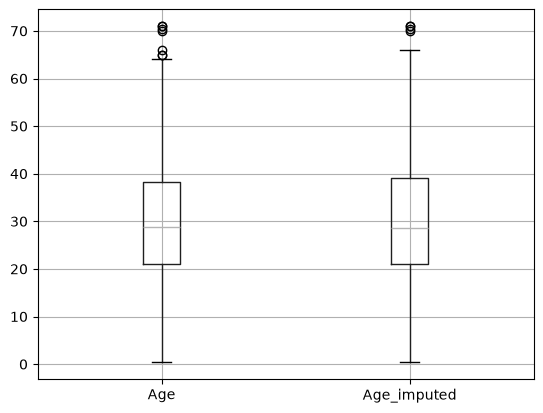

In [17]:
X_train[['Age','Age_imputed']].boxplot()

In [21]:
data= pd.read_csv('house-train.csv',usecols= ['GarageQual','FireplaceQu','SalePrice'])

In [22]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [24]:
X= data
y=data['SalePrice']

In [25]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=2)

In [26]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [27]:
X_train

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
455,TA,TA,175500,TA,TA
863,NaN,TA,132500,TA,NaN
504,Fa,TA,147000,TA,Fa
1413,Gd,TA,257000,TA,Gd
1389,Gd,TA,131000,TA,Gd
...,...,...,...,...,...
466,Po,TA,167000,TA,Po
299,Gd,TA,158500,TA,Gd
493,Fa,TA,155000,TA,Fa
527,Gd,TA,446261,TA,Gd


In [28]:
temp = pd.concat(
    [
        X_train['GarageQual'].value_counts()/len(X_train['GarageQual'].dropna()),
        X_train['GarageQual_imputed'].value_counts()/len(df)
    ],
    axis=1)

temp.columns = ['Original','imputed']

temp

,Original,imputed
TA,0.951043,1.177329
Fa,0.037171,0.046016
Gd,0.009973,0.012346
Po,0.000907,0.001122
Ex,0.000907,0.001122


In [29]:
temp = pd.concat(
    [
        X_train['FireplaceQu'].value_counts()/len(X_train['FireplaceQu'].dropna()),
        X_train['FireplaceQu_imputed'].value_counts()/len(df)
    ],
    axis=1)

temp.columns = ['Original','imputed']

temp

,Original,imputed
Gd,0.494272,0.338945
TA,0.412439,0.282828
Fa,0.040917,0.028058
Po,0.027823,0.019080
Ex,0.024550,0.016835


C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1545329637.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu']== category]['SalePrice'],hist=False,label= category)
C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1545329637.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6

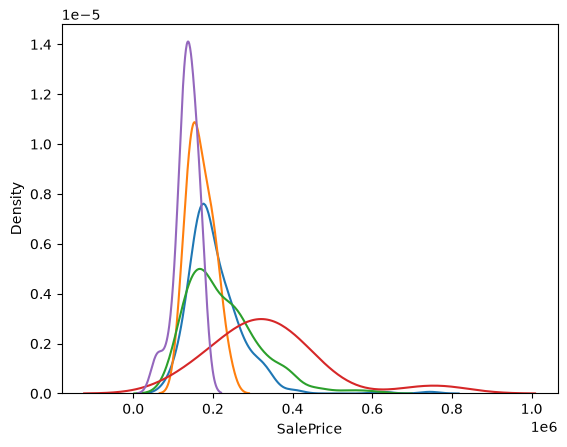

In [45]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu']== category]['SalePrice'],hist=False,label= category)
plt.show()

C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1051021867.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(X_train[X_train['FireplaceQu_imputed']== category]['SalePrice'],hist=False,label= category)
C:\Users\vaibh\AppData\Local\Temp\ipykernel_3588\1051021867.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed29

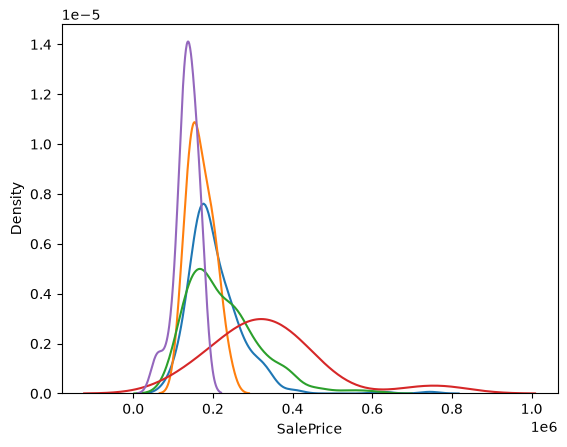

In [46]:
for category in X_train['FireplaceQu_imputed'].dropna().unique():
    sns.distplot(X_train[X_train['FireplaceQu_imputed']== category]['SalePrice'],hist=False,label= category)
plt.show()

# Missing Indicator

In [47]:
df=pd.read_csv('train.csv',usecols=['Age','Fare','Survived'])

In [48]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [74]:
X=df.drop(columns=['Survived'])
y=df['Survived']

In [81]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [83]:
X_test

,Age,Fare
707,42.0,26.2875
37,21.0,8.0500
615,24.0,65.0000
169,28.0,56.4958
68,17.0,7.9250
...,...,...
89,24.0,8.0500
80,22.0,9.0000
846,NaN,69.5500
870,26.0,7.8958


In [82]:
X_train

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458
...,...,...
534,30.0,8.6625
584,NaN,8.7125
493,71.0,49.5042
527,NaN,221.7792


In [55]:
from sklearn.impute import MissingIndicator,SimpleImputer

In [57]:
si = SimpleImputer()
X_train_trf = si.fit_transform(X_train)
X_test_trf = si.transform(X_test)


In [58]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()
clf.fit(X_train_trf,y_train)

y_pred = clf.predict(X_test_trf)

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.6145251396648045

In [59]:
mi= MissingIndicator()

mi.fit(X_train)

MissingIndicator()

In [60]:
mi.features_

array([0])

In [61]:
X_train_missing = mi.transform(X_train)

In [63]:
X_test_missing = mi.transform(X_test)

In [65]:
X_test_missing

array([[False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [ True],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [ True],
       [False],
       [ True],
       [False],
       [False],
       [ True],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [False],
       [

In [66]:
X_train['Age_NA']= X_train_missing

In [67]:
X_test['Age_NA'] = X_test_missing

In [68]:
X_train

,Age,Fare,Age_NA
30,40.0,27.7208,False
10,4.0,16.7000,False
873,47.0,9.0000,False
182,9.0,31.3875,False
876,20.0,9.8458,False
...,...,...,...
534,30.0,8.6625,False
584,NaN,8.7125,True
493,71.0,49.5042,False
527,NaN,221.7792,True


In [69]:
X_test

,Age,Fare,Age_NA
707,42.0,26.2875,False
37,21.0,8.0500,False
615,24.0,65.0000,False
169,28.0,56.4958,False
68,17.0,7.9250,False
...,...,...,...
89,24.0,8.0500,False
80,22.0,9.0000,False
846,NaN,69.5500,True
870,26.0,7.8958,False


In [70]:
si = SimpleImputer()

X_train_trf2 = si.fit_transform(X_train)
X_test_trf2 = si.transform(X_test)

In [72]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()
clf.fit(X_train_trf2,y_train)

y_pred = clf.predict(X_test_trf2)

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.6312849162011173

# Easy method to  handl missing values

In [73]:
si = SimpleImputer(add_indicator=True)

In [84]:
X_train = si.fit_transform(X_train)
X_test = si.transform(X_test)


In [86]:
from sklearn.linear_model import LogisticRegression

clf = LogisticRegression()
clf.fit(X_train,y_train)

y_pred = clf.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.6312849162011173